# Evaluation report: what is a dispute-risk score worth?

This notebook walks through the cost-weighted evaluation behind `cbp evaluate`
([generated report](../docs/evaluation/report.md), [model card](../docs/evaluation/model_card.md)).
It regenerates the **synthetic** dataset in memory, trains both baselines on the label-aware time
split, and asks the question a payments team actually cares about: *if we act on these scores,
how many dollars do we save, and how sure are we?*

> All data is synthetic. Dollar assumptions are illustrative defaults in `CostModel`.

Run it with `uv run --with jupyter jupyter lab notebooks/evaluation.ipynb`. Set
`CBP_NB_CUSTOMERS` to a smaller number for a quicker run.

In [ ]:
import os

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import NullLocator

from chargeback_prediction.evaluation import (
    CostModel,
    EvaluationConfig,
    dispute_categories,
    run_evaluation,
)
from chargeback_prediction.features import build_features
from chargeback_prediction.modeling import FeatureMatrix
from chargeback_prediction.synthetic import GeneratorConfig, generate

N_CUSTOMERS = int(os.environ.get("CBP_NB_CUSTOMERS", GeneratorConfig().n_customers))
RESAMPLES = int(os.environ.get("CBP_NB_RESAMPLES", 1_000))
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

## 1. Data and models

Same pipeline as the CLI: generate → point-in-time features → time split with a 120-day label
gap → logistic regression and gradient boosting. The evaluation-only `dispute_category`
(friendly-fraud "consumer" vs. stolen-card "fraud") never reaches the model; it is used only to
break results down below.

In [ ]:
table = build_features(generate(GeneratorConfig(n_customers=N_CUSTOMERS)))
matrix = FeatureMatrix.from_table(table)
costs = CostModel()
report = run_evaluation(
    matrix,
    categories=dispute_categories(table),
    config=EvaluationConfig(costs=costs, n_resamples=RESAMPLES),
)
test = report.baseline.split.test
y, amounts = test.y, report.amounts
print(f"test window: {len(test):,} charges, {int(y.sum())} disputes ({y.mean():.2%})")
for m in report.models:
    print(f"{m.kind.label:<20} PR-AUC {m.pr_auc.format()}")

test window: 7,013 charges, 167 disputes (2.38%)
Logistic regression  PR-AUC 0.345 [0.269, 0.431]
Gradient boosting    PR-AUC 0.227 [0.163, 0.301]


## 2. Ranking: do disputes score higher?

Scores are probabilities, so a log axis is the natural view: most charges sit well under 1%,
and the useful separation happens in the tail.

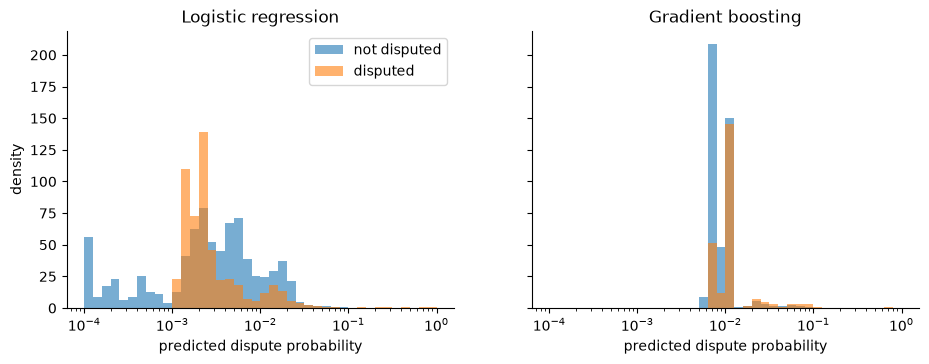

In [ ]:
fig, axes = plt.subplots(1, len(report.models), figsize=(11, 3.6), sharey=True)
axes = np.atleast_1d(axes)
bins = np.logspace(-4, 0, 41)
for ax, m in zip(axes, report.models, strict=True):
    p = np.clip(m.ranking.scores, 1e-4, 1)
    ax.hist(p[~y], bins=bins, alpha=0.6, density=True, label="not disputed")
    ax.hist(p[y], bins=bins, alpha=0.6, density=True, label="disputed")
    ax.set(xscale="log", title=m.kind.label, xlabel="predicted dispute probability")
axes[0].set_ylabel("density")
axes[0].legend()
plt.show()

## 3. Calibration: does 30% mean 30%?

The expected-cost rule multiplies the probability by dollars, so calibration is not cosmetic.
Quantile bins give each point equal weight despite the 2% base rate.

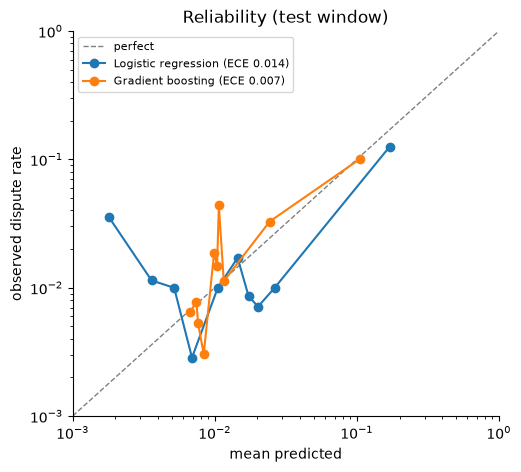

In [ ]:
fig, ax = plt.subplots(figsize=(5.5, 5))
lo = 1e-3
ax.plot([lo, 1], [lo, 1], ls="--", color="grey", lw=1, label="perfect")
for m in report.models:
    cal = m.ranking.calibration
    ax.plot(
        [b.mean_predicted for b in cal],
        [max(b.observed_rate, lo) for b in cal],
        marker="o",
        label=f"{m.kind.label} (ECE {m.ranking.ece:.3f})",
    )
ax.set(
    xscale="log",
    yscale="log",
    xlim=(lo, 1),
    ylim=(lo, 1),
    xlabel="mean predicted",
    ylabel="observed dispute rate",
    title="Reliability (test window)",
)
ax.legend(fontsize=8)
plt.show()

## 4. The decision: block when expected chargeback cost beats expected false-decline cost

A chargeback costs the unrecovered amount plus fees and handling; a false decline costs lost
margin plus churn risk. Both scale with the amount, so the break-even probability depends on the
amount too. Each dot is a test charge; charges above the line get blocked.

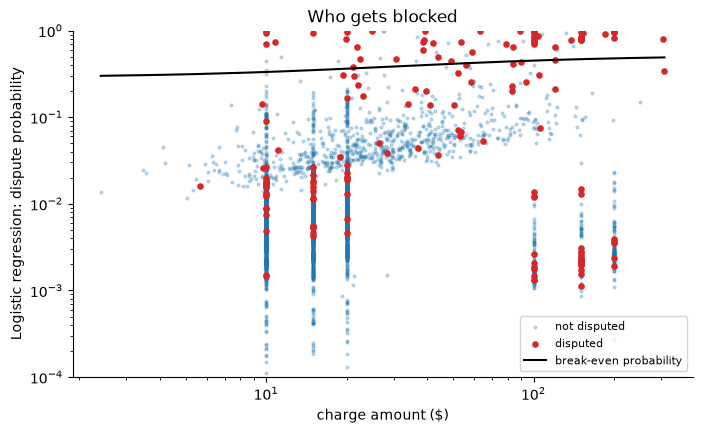

In [ ]:
best = report.recommended()
grid = np.linspace(max(amounts.min(), 1), amounts.max(), 200)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(amounts[~y], best.ranking.scores[~y], s=4, alpha=0.25, label="not disputed")
ax.scatter(amounts[y], best.ranking.scores[y], s=14, color="C3", label="disputed")
ax.plot(grid, costs.break_even_probability(grid), color="k", lw=1.5, label="break-even probability")
ax.set(
    xscale="log",
    yscale="log",
    ylim=(1e-4, 1),
    xlabel="charge amount ($)",
    ylabel=f"{best.kind.label}: dispute probability",
    title="Who gets blocked",
)
ax.legend(fontsize=8, loc="lower right")
plt.show()

## 5. Dollars saved

Blocking the top *k* charges by score traces a savings curve: it rises while blocked charges
are mostly real disputes, peaks, then falls as false declines dominate. The expected-cost rule
lands near the peak without seeing any labels; the "best threshold in hindsight" in the report
is the peak chosen *with* the labels, an unattainable upper bound for any single threshold.

Logistic regression  expected-cost rule saves $611 per 1k charges (95% CI $360 to $850), blocking 1.17%
Gradient boosting    expected-cost rule saves $273 per 1k charges (95% CI $117 to $437), blocking 0.47%


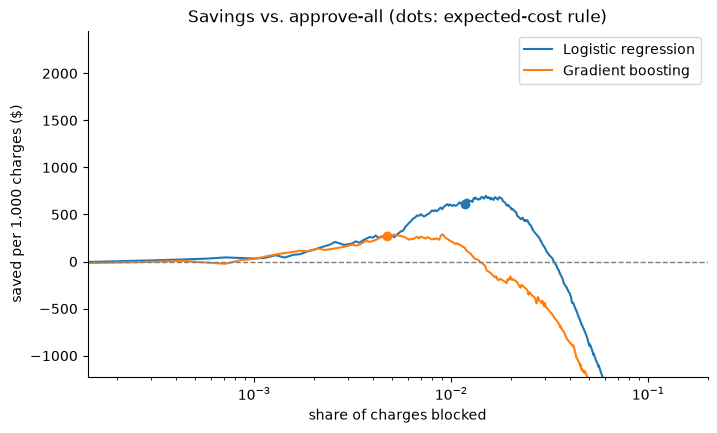

In [ ]:
n = len(test)
base_per_1k = report.approve_all.cost_per_1k
fig, ax = plt.subplots(figsize=(8, 4.5))
for m in report.models:
    share = m.curve.blocked[1:] / n
    (line,) = ax.plot(share, base_per_1k - 1_000 * m.curve.total_cost[1:] / n, label=m.kind.label)
    r = m.expected_cost
    ax.plot(max(r.block_rate, 1 / n), base_per_1k - r.cost_per_1k, "o", color=line.get_color())
    s = m.savings_per_1k
    print(
        f"{m.kind.label:<20} expected-cost rule saves ${s.estimate:,.0f} per 1k charges "
        f"(95% CI ${s.low:,.0f} to ${s.high:,.0f}), blocking {r.block_rate:.2%}"
    )
ax.axhline(0, color="grey", lw=1, ls="--")
ax.set(
    xscale="log",
    xlim=(1 / n, 0.2),
    ylim=(-base_per_1k / 2, base_per_1k),
    xlabel="share of charges blocked",
    ylabel="saved per 1,000 charges ($)",
    title="Savings vs. approve-all (dots: expected-cost rule)",
)
ax.legend()
plt.show()

## 6. Is the better model really better?

Two overlapping confidence intervals do not mean "no difference". A **paired** bootstrap scores
both models on the same resampled rows, so shared noise cancels.

In [ ]:
for c in report.comparisons:
    print(f"{c.better.label} - {c.worse.label}:")
    print(f"  PR-AUC difference        {c.pr_auc_difference.format('+.3f')}")
    s = c.savings_difference_per_1k
    print(f"  saving difference / 1k   ${s.estimate:,.0f} [${s.low:,.0f}, ${s.high:,.0f}]")

Logistic regression - Gradient boosting:
  PR-AUC difference        +0.118 [+0.047, +0.194]
  saving difference / 1k   $338 [$120, $558]


## 7. What gets caught, and how fragile is the decision?

Stolen-card fraud has loud signals (velocity, disposable email, IP/BIN mismatch); friendly fraud
looks like an ordinary renewal, so it is caught far less often. The right-hand chart scales the
false-decline cost: the rule re-derives its cut-off from the costs, with no retraining, and still
saves money when false declines are four times pricier.

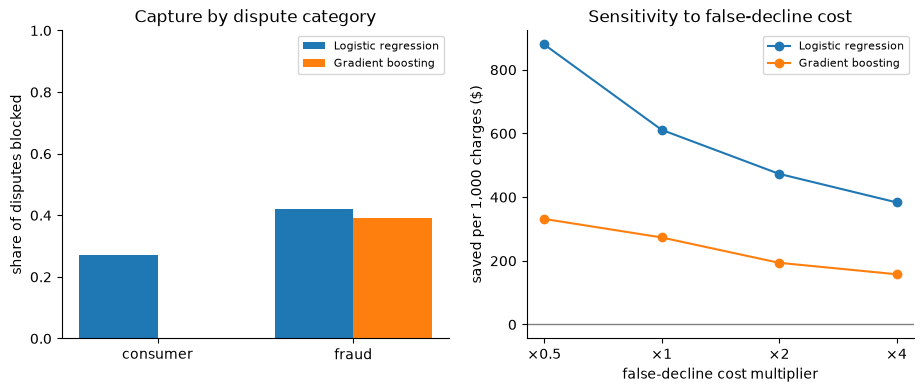

In [ ]:
fig, (ax_cat, ax_sens) = plt.subplots(1, 2, figsize=(11, 4))
width = 0.8 / len(report.models)
cats = [c.category for c in report.models[0].categories]
for i, m in enumerate(report.models):
    ax_cat.bar(
        np.arange(len(cats)) + i * width, [c.rate for c in m.categories], width, label=m.kind.label
    )
    ax_sens.plot(
        [r.false_decline_multiplier for r in m.sensitivity],
        [r.savings_per_1k for r in m.sensitivity],
        marker="o",
        label=m.kind.label,
    )
ax_cat.set_xticks(np.arange(len(cats)) + width * (len(report.models) - 1) / 2, cats)
ax_cat.set(ylim=(0, 1), ylabel="share of disputes blocked", title="Capture by dispute category")
ax_cat.legend(fontsize=8)
ax_sens.axhline(0, color="grey", lw=1)
ax_sens.set(
    xscale="log",
    xlabel="false-decline cost multiplier",
    ylabel="saved per 1,000 charges ($)",
    title="Sensitivity to false-decline cost",
)
multipliers = [r.false_decline_multiplier for r in report.models[0].sensitivity]
ax_sens.xaxis.set_minor_locator(NullLocator())
ax_sens.set_xticks(multipliers, [f"×{x:g}" for x in multipliers])
ax_sens.legend(fontsize=8)
plt.show()

## Takeaways

- **Rank quality and dollars agree here**, but the gap in dollars is what justifies picking one
  model over another; report it with a paired interval.
- **Calibration is what makes the expected-cost rule work** without tuning a threshold on labels
  the merchant will not have for months.
- **Friendly fraud is the hard part.** Blocking is the wrong tool for most of it; clearer
  descriptors, pre-renewal reminders and easy cancellation attack it at the source, and the
  representment playbook handles what remains.
- **Everything is synthetic.** Treat the numbers as a demonstration of the method.